# 10 — Privacy Risk Evaluation

**Capstone:** Comparative Evaluation of Diffusion, GAN, and VAE Models for Synthetic Clinical Tabular Data Generation.

This notebook compares **TVAE 50**, **TVAE 300**, **CTGAN 300**, and **TabDDPM 100** for possible **training-record memorization**. It uses the already saved synthetic CSVs; **no generator training happens here**.

Three complementary, **empirical risk indicators**:
1. Exact/full-row matches to real training versus held-out real test rows.
2. Sample-based nearest-neighbor distances to synthetic records.
3. Sample-based train-vs-held-out membership-discrimination AUC using distance to synthetic data.

**Important:** These measures do **not** establish differential privacy, legal de-identification, or release safety. Data may be re-identifiable even when no exact duplicates appear. All risk metrics depend on their attack assumptions, representation, and sampling.

## 1. Setup and paths
Select the DGX `.venv` kernel. This notebook writes only to `results/privacy/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score

SEED = 42
ROOT = Path.cwd().resolve()
if not (ROOT / "data/processed/train_semantic.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/processed/train_semantic.csv").exists(), "Open notebook from your DGX project"
OUT = ROOT / "results/privacy"
OUT.mkdir(parents=True, exist_ok=True)
META = ROOT / "data/processed/preprocessing_metadata.json"
TRAIN = ROOT / "data/processed/train_semantic.csv"
TEST = ROOT / "data/processed/test_semantic.csv"
SYN_PATHS = {
    "TVAE 50": ROOT / "data/synthetic/tvae_50ep.csv",
    "TVAE 300": ROOT / "data/synthetic/tvae_300ep.csv",
    "CTGAN 300": ROOT / "data/synthetic/ctgan_300ep.csv",
    "TabDDPM 100": ROOT / "data/synthetic/tabddpm_joint_100ep.csv",
}
print("Project:", ROOT)
print("Results folder:", OUT.relative_to(ROOT))

Project: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation
Results folder: results/privacy


## 2. Load the same patient-disjoint data split
The **training records** were potentially used by the generators; the **real held-out test records** were not. Both are used here only for privacy auditing (no training or generator tuning).

In [2]:
meta = json.loads(META.read_text(encoding="utf-8"))
NUM = list(meta["numerical_feature_columns"])
CAT = list(meta["categorical_feature_columns"])
TARGET = meta["target_column"]
COLS = NUM + CAT + [TARGET]
assert len(NUM) == 8 and len(CAT) == 36 and TARGET == "readmitted_30"

real_train = pd.read_csv(TRAIN)
real_test = pd.read_csv(TEST)
synth = {name: pd.read_csv(path) for name, path in SYN_PATHS.items()}
for name, df in [("Real train", real_train), ("Real held-out test", real_test)] + list(synth.items()):
    assert set(df.columns) == set(COLS), f"Columns mismatch: {name}"
    assert df[TARGET].notna().all(), f"Missing readmission target: {name}"
    assert pd.to_numeric(df[TARGET]).isin([0, 1]).all(), f"Invalid label: {name}"
assert len(real_train) == 79567 and len(real_test) == 19773
assert all(len(df) == len(real_train) for df in synth.values())
summary = pd.DataFrame([{"dataset":name, "rows":len(df),
                         "positive_pct":round(100*pd.to_numeric(df[TARGET]).mean(),3)}
                        for name,df in [("Real train",real_train),("Real test",real_test)] + list(synth.items())])
display(summary)
print("Data validation PASSED. No generative model is being retrained.")

,dataset,rows,positive_pct
0,Real train,79567,11.399
1,Real test,19773,11.349
2,TVAE 50,79567,0.000
3,TVAE 300,79567,0.043
4,CTGAN 300,79567,4.121
5,TabDDPM 100,79567,10.566


Data validation PASSED. No generative model is being retrained.


## 3. Exact full-row matches (all 45 columns)
A full-row match may arise from a common combination of clinical variables, even if the generator did not copy a patient. These rows **do not contain patient IDs**. We count matches to both train and test as a reference. Numeric columns are rounded to 6 decimals solely to normalize CSV formatting.

In [3]:
def row_hashes(frame):
    # Standardize value representations; preserve all categorical values and label.
    canonical = pd.DataFrame(index=frame.index)
    for c in NUM:
        values = pd.to_numeric(frame[c], errors="coerce").round(6)
        canonical[c] = values.map(lambda v: "__NA__" if pd.isna(v) else f"{v:.6f}")
    for c in CAT + [TARGET]:
        canonical[c] = frame[c].astype("string").fillna("__NA__").astype(str)
    return pd.util.hash_pandas_object(canonical[COLS], index=False).to_numpy()

train_hash = set(row_hashes(real_train))
test_hash = set(row_hashes(real_test))
match_rows = []
for name,df in synth.items():
    hashed = row_hashes(df)
    hits_train = np.fromiter((h in train_hash for h in hashed), dtype=bool, count=len(hashed))
    hits_test = np.fromiter((h in test_hash for h in hashed), dtype=bool, count=len(hashed))
    y = pd.to_numeric(df[TARGET]).astype(int).to_numpy()
    match_rows.append({"model":name,"rows":len(df),
                       "exact_train_matches":int(hits_train.sum()),
                       "exact_train_match_pct":round(100*hits_train.mean(),4),
                       "exact_test_matches":int(hits_test.sum()),
                       "exact_test_match_pct":round(100*hits_test.mean(),4),
                       "train_matches_with_positive_label":int((hits_train & (y==1)).sum())})
exact = pd.DataFrame(match_rows).set_index("model")
display(exact)
exact.to_csv(OUT / "exact_full_row_matches.csv")
print("Saved:", OUT / "exact_full_row_matches.csv")

,rows,exact_train_matches,exact_train_match_pct,exact_test_matches,exact_test_match_pct,train_matches_with_positive_label
model,,,,,,
TVAE 50,79567,0,0.0,0,0.0,0
TVAE 300,79567,0,0.0,0,0.0,0
CTGAN 300,79567,0,0.0,0,0.0,0
TabDDPM 100,79567,0,0.0,0,0.0,0


Saved: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation/results/privacy/exact_full_row_matches.csv


## 4. Sample-based proximity and membership-risk proxy
To keep computation practical, we take the **same random 1,000 real train and 1,000 held-out real test records across all models**. For each generator, we take 5,000 synthetic rows, without replacement.

Distance representation: fit numeric standardization and categorical vocabulary **on real training data only**; clip standardized numeric values to ±5, and one-hot encode categorical fields (including `readmitted_30`) so numeric-looking IDs are not treated as continuous quantities. Numerical and categorical feature weight choices are heuristic.

For each real query, compute distance to its nearest sampled synthetic row. An exploratory membership classifier assigns greater membership likelihood to real rows that are closer to the synthetic data. **AUC ≈ 0.5** means this simple proximity attack cannot distinguish training from held-out records on the sampled audit, **not** that the model guarantees privacy. **AUC above 0.5** indicates a potential train-specific proximity signal; below 0.5 may reflect sampling or distribution differences. This is not a full adaptive membership-inference attack.

In [4]:
REAL_QUERY_N = 1000
SYN_POOL_N = 5000
rng = np.random.default_rng(SEED)
train_idx = rng.choice(len(real_train), size=REAL_QUERY_N, replace=False)
test_idx = rng.choice(len(real_test), size=REAL_QUERY_N, replace=False)

# Treat the readmission target as categorical for joint-record proximity.
ALL_CAT = CAT + [TARGET]

def numeric_matrix(frame):
    return (frame[NUM].apply(pd.to_numeric, errors="coerce")
            .replace([np.inf,-np.inf],np.nan))

def categoricals(frame):
    return frame[ALL_CAT].astype("string").fillna("__NA__").astype(str)

numeric_train = numeric_matrix(real_train)
train_medians = numeric_train.median()
num_scaler = StandardScaler().fit(numeric_train.fillna(train_medians))
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
encoder.fit(categoricals(real_train))

def representation(frame):
    # 1 categorical mismatch contributes about 1 squared-distance unit.
    x_num = numeric_matrix(frame).fillna(train_medians)
    x_num = np.clip(num_scaler.transform(x_num).astype(np.float32), -5, 5)
    x_cat = encoder.transform(categoricals(frame)) / np.sqrt(np.float32(2.0))
    return np.hstack([x_num, x_cat]).astype(np.float32)

q_train = representation(real_train.iloc[train_idx])
q_test = representation(real_test.iloc[test_idx])
labels_train = pd.to_numeric(real_train.iloc[train_idx][TARGET]).to_numpy()
labels_test = pd.to_numeric(real_test.iloc[test_idx][TARGET]).to_numpy()
print(f"Queries: {len(q_train)} real train + {len(q_test)} real held-out")
print(f"Synthetic reference per model: {SYN_POOL_N}")
print("Representation dimension:", q_train.shape[1])

Queries: 1000 real train + 1000 real held-out
Synthetic reference per model: 5000
Representation dimension: 257


In [5]:
distance_rows = []
distance_distributions = {}
for name,df in synth.items():
    idx = np.random.default_rng(SEED).choice(len(df), size=SYN_POOL_N, replace=False)
    reference = representation(df.iloc[idx])
    nn = NearestNeighbors(n_neighbors=1, algorithm="brute", metric="euclidean", n_jobs=4)
    nn.fit(reference)
    d_train = nn.kneighbors(q_train, return_distance=True)[0][:, 0]
    d_test = nn.kneighbors(q_test, return_distance=True)[0][:, 0]
    membership_auc = roc_auc_score(
        np.r_[np.ones(len(d_train)), np.zeros(len(d_test))],
        -np.r_[d_train, d_test]
    )
    distance_distributions[name] = (d_train, d_test)
    train_pos = d_train[labels_train==1]
    test_pos = d_test[labels_test==1]
    distance_rows.append({
        "model":name, "train_query_n":len(d_train),"test_query_n":len(d_test),
        "synthetic_pool_n":len(reference),
        "median_train_to_synth":round(float(np.median(d_train)),4),
        "median_test_to_synth":round(float(np.median(d_test)),4),
        "median_train_over_test":round(float(np.median(d_train)/max(np.median(d_test),1e-8)),4),
        "train_5pct_distance":round(float(np.quantile(d_train,0.05)),4),
        "test_5pct_distance":round(float(np.quantile(d_test,0.05)),4),
        "median_positive_train_to_synth":round(float(np.median(train_pos)),4) if len(train_pos) else np.nan,
        "median_positive_test_to_synth":round(float(np.median(test_pos)),4) if len(test_pos) else np.nan,
        "proximity_membership_auc":round(float(membership_auc),4),
    })
    print(f"{name:12s} | train median={np.median(d_train):.3f} | test median={np.median(d_test):.3f} | proximity AUC={membership_auc:.3f}",flush=True)

proximity = pd.DataFrame(distance_rows).set_index("model")
display(proximity)
proximity.to_csv(OUT / "sample_nearest_neighbor_privacy.csv")
print("Saved:",OUT / "sample_nearest_neighbor_privacy.csv")

TVAE 50      | train median=2.626 | test median=2.628 | proximity AUC=0.496
TVAE 300     | train median=2.576 | test median=2.579 | proximity AUC=0.500
CTGAN 300    | train median=2.833 | test median=2.822 | proximity AUC=0.491
TabDDPM 100  | train median=2.618 | test median=2.630 | proximity AUC=0.499


,train_query_n,test_query_n,synthetic_pool_n,median_train_to_synth,median_test_to_synth,median_train_over_test,train_5pct_distance,test_5pct_distance,median_positive_train_to_synth,median_positive_test_to_synth,proximity_membership_auc
model,,,,,,,,,,,
TVAE 50,1000,1000,5000,2.6262,2.6279,0.9993,1.8742,1.8003,2.9468,3.0173,0.4964
TVAE 300,1000,1000,5000,2.5765,2.5785,0.9992,1.9313,1.8564,2.9129,2.8979,0.4996
CTGAN 300,1000,1000,5000,2.8326,2.8217,1.0039,2.2187,2.1905,3.0226,3.1032,0.4907
TabDDPM 100,1000,1000,5000,2.6178,2.6298,0.9955,2.0906,2.0155,2.7954,2.8539,0.4987


Saved: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation/results/privacy/sample_nearest_neighbor_privacy.csv


## 5. Plot proximity AUC and exact matches
AUC is **not a certified privacy score**, and exact matches cannot by themselves establish patient disclosure. Read these together with the train-vs-test distance distributions and the study limitations.

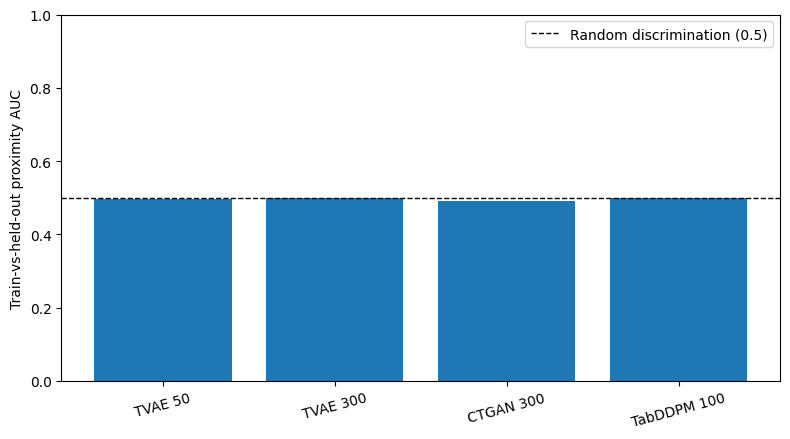

Saved: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation/results/privacy/proximity_membership_auc.png


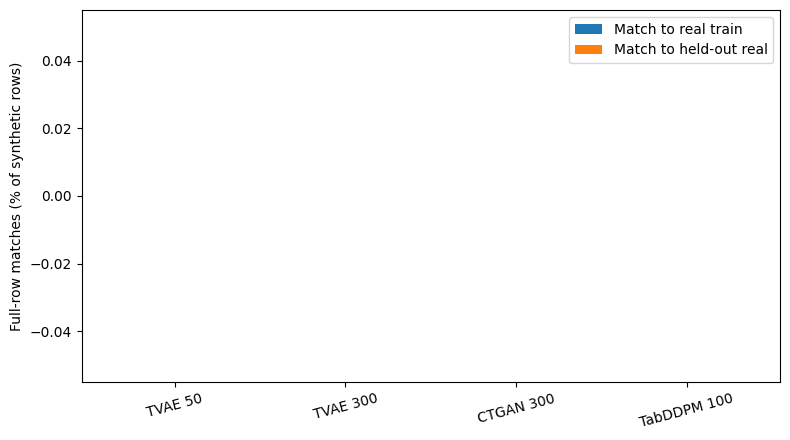

Saved: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation/results/privacy/exact_match_comparison.png


In [6]:
fig, ax = plt.subplots(figsize=(8,4.5))
models = proximity.index.tolist()
auc_values = proximity["proximity_membership_auc"].to_numpy(dtype=float)
ax.bar(models, auc_values)
ax.axhline(0.5, color="black", ls="--", lw=1, label="Random discrimination (0.5)")
ax.set_ylim(0,1)
ax.set_ylabel("Train-vs-held-out proximity AUC")
ax.tick_params(axis="x",rotation=15)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(OUT / "proximity_membership_auc.png",dpi=170,bbox_inches="tight")
plt.show()
print("Saved:",OUT / "proximity_membership_auc.png")

fig, ax = plt.subplots(figsize=(8,4.5))
x = np.arange(len(exact)); width=0.36
ax.bar(x-width/2,exact["exact_train_match_pct"],width,label="Match to real train")
ax.bar(x+width/2,exact["exact_test_match_pct"],width,label="Match to held-out real")
ax.set_xticks(x, exact.index, rotation=15)
ax.set_ylabel("Full-row matches (% of synthetic rows)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "exact_match_comparison.png",dpi=170,bbox_inches="tight")
plt.show()
print("Saved:",OUT / "exact_match_comparison.png")

## 6. Save protocol and interpret cautiously

**Reporting checklist**

- State that synthetic datasets each contain 79,567 rows and that the real training/test partitions are patient-disjoint.
- Note that exact duplicates of common clinical profiles do **not** identify individuals.
- Note that the nearest-neighbor analysis uses only a sample of synthetic rows and an arbitrary, documented distance representation; changing sampling, distance or attack assumptions can change results.
- A proximity membership AUC around 0.5 is *not* proof of safety; a high AUC is a **risk flag**, not a demonstrated successful real-world attack.
- These checks do **not** measure attribute inference, linkage using external information, differential-privacy guarantees, or compliance with privacy law.
- Do not publish individual-level training/test data or synthetic records as a public demo without approval and further risk review.
- Avoid tuning generators based on held-out test/privacy records; future retuning needs a separate validation split.

**Next:** Consolidate fidelity, TSTR utility, and privacy findings in a comparison table. Do not name a privacy winner based on one heuristic metric.

In [7]:
protocol = {
    "experiment": "Sample-based privacy-risk indicators (not privacy certification)",
    "seed": SEED, "train_rows": len(real_train), "held_out_rows": len(real_test),
    "queries_per_group": REAL_QUERY_N, "synthetic_pool_per_model": SYN_POOL_N,
    "features": {"numerical":NUM, "categorical":CAT, "target":TARGET},
    "distance": "Euclidean on real-train standardized and [-5,5] clipped numeric features + real-train-fitted one-hot categorical fields including target, with each one-hot scaled by 1/sqrt(2)",
    "attack_proxy": "AUC for distinguishing sampled real train vs held-out real test by negative nearest-synthetic distance",
    "limitations": "Heuristic and sample-based; not differential privacy, not exhaustive membership inference, and not clearance for public release",
    "files": ["exact_full_row_matches.csv","sample_nearest_neighbor_privacy.csv","proximity_membership_auc.png","exact_match_comparison.png"]
}
(OUT / "privacy_protocol.json").write_text(json.dumps(protocol, indent=2), encoding="utf-8")
print("Privacy risk indicators saved under:", OUT)
print("IMPORTANT: These are exploratory risk proxies, not a guarantee of privacy.")

Privacy risk indicators saved under: /home/ayanasanthosh.ds25a/synthetic-clinical-data-generation/results/privacy
IMPORTANT: These are exploratory risk proxies, not a guarantee of privacy.
